# 08 — Interpretabilidade com Grad-CAM

**TCC UNIP 2026** · Etapa 8 de 9 do pipeline · Seção 4.5.8 do trabalho escrito.

**Objetivo:** gerar os mapas Grad-CAM, sempre para a classe predita, nos quatro grupos de exemplos selecionados do conjunto de teste.

**Entradas:**
- `modelo_resnet50.pt`, `modelo_efficientnet_b0.pt` e `config_final.json` (notebook 06)
- `test.csv` e imagens de teste (notebook 03)

**Saídas:**
- `gradcam/` (grades de mapas Grad-CAM por grupo e arquitetura)

Antes de executar: no Colab, selecione *Ambiente de execução → Alterar tipo de ambiente de execução → GPU* (necessário a partir do notebook 05). As saídas exibidas foram preservadas da execução original do notebook único.

In [ ]:
# Parâmetro: True usa o Google Drive para guardar os arquivos entre notebooks;
# False usa só o disco da sessão atual. Quando o notebook é executado pelo
# 00_executar_todos.ipynb, vale o valor definido lá.
if "USAR_DRIVE" not in globals():
    USAR_DRIVE = True


In [ ]:
# ============================================================
# PERSISTÊNCIA ENTRE NOTEBOOKS (Google Drive)
# ============================================================
# Cada notebook roda em uma sessão própria do Colab. Para que os arquivos gerados por um
# notebook fiquem disponíveis para os seguintes, a pasta /content/data é ligada a uma
# pasta no Google Drive. O valor de USAR_DRIVE é definido na célula anterior.
PASTA_DRIVE = "/content/drive/MyDrive/TCC_UNIP/data"

import os
if USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(PASTA_DRIVE, exist_ok=True)
    if not os.path.islink("/content/data"):
        if os.path.isdir("/content/data"):
            if os.listdir("/content/data"):
                raise RuntimeError("/content/data já contém arquivos: mova-os para a pasta do Drive antes de continuar.")
            os.rmdir("/content/data")
        os.symlink(PASTA_DRIVE, "/content/data")
print("Pasta de dados:", os.path.realpath("/content/data"))


## Funções do pipeline de dados (reutilizadas do notebook 04)

In [ ]:
# [Célula reutilizada de 03_preprocessamento.ipynb]
import os
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from tqdm import tqdm


In [ ]:
# [Célula reutilizada de 03_preprocessamento.ipynb]
SEED = 42
PROPORCAO_TREINO = 0.70
PROPORCAO_VAL = 0.15
PROPORCAO_TESTE = 0.15

# Mantido por compatibilidade com a estrutura original. Na versão corrigida, imagens sem
# lesion_id são mantidas e viram grupos próprios, salvo quando ligadas por pHash a duplicatas.
INCLUIR_SEM_LESION_ID = True

In [ ]:
# [Célula reutilizada de 04_pipeline_dados_pytorch.ipynb]
import pandas as pd
import cv2
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

In [ ]:
# [Célula reutilizada de 04_pipeline_dados_pytorch.ipynb]
SAIDA_BASE = "/content/data/processed"
MEAN_IMAGENET = [0.485, 0.456, 0.406]
STD_IMAGENET = [0.229, 0.224, 0.225]
BATCH_SIZE = 32
NUM_WORKERS = 2   # o Colab tem 2 CPUs; mais workers que isso só atrapalha (ver aviso do DataLoader)

# Modo de teste rápido (opcional): use p.ex. 0.05 para treinar/avaliar com ~5% das imagens
# e conferir se o notebook inteiro roda, antes de gastar horas de GPU. None = usa tudo.
FRACAO_DADOS_DEBUG = None

In [ ]:
# [Célula reutilizada de 04_pipeline_dados_pytorch.ipynb]
# ============================================================
# TRANSFORMS
# ============================================================
# ATENÇÃO (teste de cor): o ColorJitter do Albumentations, quando 'hue' não é informado, aplica
# uma rotação de MATIZ por padrão (nas versões 2.x: até ±0.5 do círculo cromático, i.e. qualquer cor).
# Isso muda a cor da lesão — um sinal clínico central (critério "C" do ABCDE) — em metade das imagens.
# Esta é a configuração da versão anterior e é mantida como variante "original" para comparação.
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.3),
    A.Normalize(mean=MEAN_IMAGENET, std=STD_IMAGENET),
    ToTensorV2(),
])

# Val/teste: SEM augmentation aleatório — só normalização, para avaliação justa e reprodutível
eval_transform = A.Compose([
    A.Normalize(mean=MEAN_IMAGENET, std=STD_IMAGENET),
    ToTensorV2(),
])

# ------------------------------------------------------------
# Variantes de augmentation de COR (usadas no "Teste de alterações de cor")
#   "original"         -> a configuração acima (brilho, contraste, saturação E matiz padrão do Albumentations)
#   "brilho_contraste" -> só brilho e contraste (±20%); saturação e matiz FIXOS (cor da lesão preservada)
#   "sem_cor"          -> nenhuma alteração de cor (só flips/rotações/escala)
# ------------------------------------------------------------
def construir_train_transform(variante_cor="original"):
    if variante_cor == "original":
        return train_transform
    if variante_cor == "brilho_contraste":
        cor = [A.ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2),
                             saturation=(1.0, 1.0), hue=(0.0, 0.0), p=0.5)]
    elif variante_cor == "sem_cor":
        cor = []
    else:
        raise ValueError(f"Variante de cor desconhecida: {variante_cor}")
    return A.Compose([
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        *cor,
        A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.3),
        A.Normalize(mean=MEAN_IMAGENET, std=STD_IMAGENET),
        ToTensorV2(),
    ])

TRAIN_TRANSFORMS = {v: construir_train_transform(v)
                    for v in ["original", "brilho_contraste", "sem_cor"]}

In [ ]:
# [Célula reutilizada de 04_pipeline_dados_pytorch.ipynb]
# ============================================================
# DATASET
# ============================================================
from PIL import Image, ImageEnhance

def aplicar_perturbacao_cor(img_rgb, brilho=0.0, contraste=0.0, saturacao=0.0, matiz=0.0):
    """Perturbação DETERMINÍSTICA de cor (usada só na avaliação de robustez, nunca no treino).
    brilho/contraste/saturacao: variação relativa (0.2 = +20%, -0.2 = -20%).
    matiz: fração do círculo cromático (0.1 = 36 graus)."""
    pil = Image.fromarray(img_rgb)
    if brilho:
        pil = ImageEnhance.Brightness(pil).enhance(1.0 + brilho)
    if contraste:
        pil = ImageEnhance.Contrast(pil).enhance(1.0 + contraste)
    if saturacao:
        pil = ImageEnhance.Color(pil).enhance(1.0 + saturacao)
    if matiz:
        h, s, v = pil.convert("HSV").split()
        deslocamento = int(round(matiz * 255))
        h = h.point(lambda x: (x + deslocamento) % 256)
        pil = Image.merge("HSV", (h, s, v)).convert("RGB")
    return np.array(pil)


class DermatoDataset(Dataset):
    def __init__(self, dataframe, mapa_classes, transform=None, perturbacao=None):
        self.df = dataframe.reset_index(drop=True)
        self.mapa_classes = mapa_classes
        self.transform = transform
        self.perturbacao = perturbacao   # dict p/ aplicar_perturbacao_cor (None = sem perturbação)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        linha = self.df.iloc[idx]
        img = cv2.imread(linha["caminho_processado"])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if self.perturbacao:
            img = aplicar_perturbacao_cor(img, **self.perturbacao)

        if self.transform:
            img = self.transform(image=img)["image"]

        rotulo = self.mapa_classes[linha["classe"]]
        return img, rotulo

In [ ]:
# [Célula reutilizada de 04_pipeline_dados_pytorch.ipynb]
# ============================================================
# CRIAÇÃO DOS DATALOADERS
# ============================================================
# Qual versão das imagens é usada por padrão: "com_dullrazor" (train.csv...) ou "sem_dullrazor".
# A célula de seleção da configuração final (mais adiante) atualiza este valor.
DADOS_ATIVOS = "com_dullrazor"

def caminho_csv_split(split, dados):
    sufixo = "" if dados == "com_dullrazor" else f"_{dados}"
    return f"{SAIDA_BASE}/{split}{sufixo}.csv"

def _ler_split(split, dados):
    df = pd.read_csv(caminho_csv_split(split, dados), low_memory=False)
    if FRACAO_DADOS_DEBUG:
        df = (df.groupby("classe", group_keys=False)
                .apply(lambda g: g.sample(n=max(2, int(len(g) * FRACAO_DADOS_DEBUG)),
                                          random_state=SEED)
                       if len(g) > 2 else g))
    return df

def criar_dataloaders(batch_size=BATCH_SIZE, dados=None, variante_cor="original"):
    dados = dados or DADOS_ATIVOS
    df_treino = _ler_split("train", dados)
    df_val = _ler_split("val", dados)
    df_teste = _ler_split("test", dados)

    classes_ordenadas = sorted(df_treino["classe"].unique())
    mapa_classes = {nome: idx for idx, nome in enumerate(classes_ordenadas)}
    print("Mapa de classes:", mapa_classes)
    print(f"Dados: {dados} | augmentation de cor: {variante_cor}")

    ds_treino = DermatoDataset(df_treino, mapa_classes, transform=TRAIN_TRANSFORMS[variante_cor])
    ds_val = DermatoDataset(df_val, mapa_classes, transform=eval_transform)
    ds_teste = DermatoDataset(df_teste, mapa_classes, transform=eval_transform)

    pin = torch.cuda.is_available()
    train_loader = DataLoader(ds_treino, batch_size=batch_size, shuffle=True,
                               num_workers=NUM_WORKERS, pin_memory=pin,
                               persistent_workers=NUM_WORKERS > 0)
    val_loader = DataLoader(ds_val, batch_size=batch_size, shuffle=False,
                             num_workers=NUM_WORKERS, pin_memory=pin)
    test_loader = DataLoader(ds_teste, batch_size=batch_size, shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=pin)

    return train_loader, val_loader, test_loader, mapa_classes


def criar_loader_teste(dados=None, perturbacao=None, batch_size=BATCH_SIZE):
    """DataLoader de TESTE (sem augmentation), opcionalmente com perturbação determinística
    de cor — usado na avaliação de robustez a brilho/contraste."""
    dados = dados or DADOS_ATIVOS
    df_treino = _ler_split("train", dados)
    mapa_classes = {n: i for i, n in enumerate(sorted(df_treino["classe"].unique()))}
    ds = DermatoDataset(_ler_split("test", dados), mapa_classes,
                        transform=eval_transform, perturbacao=perturbacao)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS,
                        pin_memory=torch.cuda.is_available())
    return loader, mapa_classes

In [ ]:
# ============================================================
# VERSÃO DAS IMAGENS DEFINIDA NA CONFIGURAÇÃO FINAL (06_treinamento_fine_tuning.ipynb)
# ============================================================
import json
_caminho_cfg = os.path.join(SAIDA_BASE, "experimentos", "config_final.json")
if os.path.exists(_caminho_cfg):
    with open(_caminho_cfg) as f:
        DADOS_ATIVOS = json.load(f)["config_final"]["dados"]
print("Versão das imagens utilizada:", DADOS_ATIVOS)


### GRAD-CAM E ANÁLISE QUALITATIVA

Gera mapas de calor Grad-CAM para entender ONDE cada modelo está "olhando"
ao tomar uma decisão, e organiza a análise qualitativa em quatro grupos,
que são exatamente o que interessa clinicamente:

  1. Acertos de alta confiança (o modelo aprendeu o padrão certo)
  2. Falsos negativos de melanoma (o mais grave clinicamente — o modelo
     disse "não é melanoma" quando era)
  3. Falsos positivos de melanoma (menos grave, mas gera ansiedade/
     encaminhamento desnecessário)
  4. Erros entre classes visualmente parecidas (mimetismo dermatológico,
     como discutido no referencial teórico do TCC)

Pré-requisito: pip install grad-cam

In [ ]:
!pip install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 4.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=e7fff83867ba9815b1469bbe1e5090198adedd655eb782183a5a53898fc625e0
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam


In [ ]:
import os
import torch
import torch.nn as nn
from torchvision import models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SAIDA_BASE = "/content/data/processed"
SAIDA_GRADCAM = os.path.join(SAIDA_BASE, "gradcam")
os.makedirs(SAIDA_GRADCAM, exist_ok=True)

# Ajuste este nome conforme a classe "melanoma" no seu mapa_classes
NOME_CLASSE_MELANOMA = "melanoma"

N_EXEMPLOS_POR_GRUPO = 8  # quantidade de imagens em cada grade de exemplos

In [ ]:
# ============================================================
# CARREGAMENTO DO MODELO E DA CAMADA-ALVO DO GRAD-CAM
# ============================================================
def carregar_modelo_e_camada_alvo(arquitetura, num_classes):
    if arquitetura == "resnet50":
        modelo = models.resnet50(weights=None)
        modelo.fc = nn.Linear(modelo.fc.in_features, num_classes)
        camada_alvo = modelo.layer4[-1]
    elif arquitetura == "efficientnet_b0":
        modelo = models.efficientnet_b0(weights=None)
        modelo.classifier[1] = nn.Linear(modelo.classifier[1].in_features, num_classes)
        camada_alvo = modelo.features[-1]
    else:
        raise ValueError(f"Arquitetura não suportada: {arquitetura}")

    caminho_checkpoint = os.path.join(SAIDA_BASE, f"modelo_{arquitetura}.pt")
    modelo.load_state_dict(torch.load(caminho_checkpoint, map_location=DEVICE))
    modelo.to(DEVICE)
    modelo.eval()
    return modelo, camada_alvo

In [ ]:
# ============================================================
# DESNORMALIZAÇÃO — para exibir a imagem original por trás do heatmap
# ============================================================
def desnormalizar_imagem(tensor_imagem):
    """Reverte a normalização ImageNet para exibir a imagem em RGB [0,1]."""
    img = tensor_imagem.cpu().numpy().transpose(1, 2, 0)
    mean = np.array(MEAN_IMAGENET)
    std = np.array(STD_IMAGENET)
    img = std * img + mean
    img = np.clip(img, 0, 1)
    return img

In [ ]:
# ============================================================
# COLETA DE PREDIÇÕES COM REFERÊNCIA ÀS IMAGENS (para poder gerar Grad-CAM depois)
# ============================================================
def coletar_predicoes_com_imagens(modelo, test_loader):
    registros = []

    with torch.no_grad():
        for imagens, rotulos in test_loader:
            imagens_gpu = imagens.to(DEVICE)
            saidas = modelo(imagens_gpu)
            probs = torch.softmax(saidas, dim=1).cpu().numpy()
            preds = np.argmax(probs, axis=1)

            for i in range(imagens.size(0)):
                registros.append({
                    "tensor_imagem": imagens[i],  # mantém em CPU, sem normalização revertida ainda
                    "rotulo_verdadeiro": int(rotulos[i].item()),
                    "predicao": int(preds[i]),
                    "confianca": float(probs[i, preds[i]]),
                    "prob_todas_classes": probs[i],
                })

    return registros

In [ ]:
# ============================================================
# SELEÇÃO DOS GRUPOS DE ANÁLISE QUALITATIVA
# ============================================================
def selecionar_grupos_analise(registros, mapa_classes):
    idx_melanoma = mapa_classes.get(NOME_CLASSE_MELANOMA)

    acertos_alta_confianca = sorted(
        [r for r in registros if r["predicao"] == r["rotulo_verdadeiro"]],
        key=lambda r: -r["confianca"]
    )[:N_EXEMPLOS_POR_GRUPO]

    falsos_negativos_melanoma = []
    falsos_positivos_melanoma = []
    if idx_melanoma is not None:
        falsos_negativos_melanoma = [
            r for r in registros
            if r["rotulo_verdadeiro"] == idx_melanoma and r["predicao"] != idx_melanoma
        ][:N_EXEMPLOS_POR_GRUPO]

        falsos_positivos_melanoma = [
            r for r in registros
            if r["predicao"] == idx_melanoma and r["rotulo_verdadeiro"] != idx_melanoma
        ][:N_EXEMPLOS_POR_GRUPO]

    erros_gerais = sorted(
        [r for r in registros if r["predicao"] != r["rotulo_verdadeiro"]],
        key=lambda r: -r["confianca"]  # erros com ALTA confiança são os mais preocupantes
    )[:N_EXEMPLOS_POR_GRUPO]

    return {
        "acertos_alta_confianca": acertos_alta_confianca,
        "falsos_negativos_melanoma": falsos_negativos_melanoma,
        "falsos_positivos_melanoma": falsos_positivos_melanoma,
        "erros_alta_confianca": erros_gerais,
    }

In [ ]:
# ============================================================
# GERAÇÃO DA GRADE DE GRAD-CAM PARA UM GRUPO
# ============================================================
def gerar_grade_gradcam(modelo, camada_alvo, registros_grupo, nomes_classes,
                          titulo_grupo, arquitetura):
    if not registros_grupo:
        print(f"[AVISO] Nenhum exemplo encontrado para o grupo '{titulo_grupo}'. Pulando.")
        return

    cam = GradCAM(model=modelo, target_layers=[camada_alvo])

    n = len(registros_grupo)
    colunas = min(4, n)
    linhas = (n + colunas - 1) // colunas

    fig, eixos = plt.subplots(linhas, colunas, figsize=(colunas * 4, linhas * 4.5))
    eixos = np.array(eixos).reshape(-1) if n > 1 else [eixos]

    for i, registro in enumerate(registros_grupo):
        tensor_img = registro["tensor_imagem"]
        img_desnormalizada = desnormalizar_imagem(tensor_img)

        alvo_classe = ClassifierOutputTarget(registro["predicao"])
        mapa_calor = cam(input_tensor=tensor_img.unsqueeze(0).to(DEVICE),
                          targets=[alvo_classe])[0]

        visualizacao = show_cam_on_image(img_desnormalizada, mapa_calor, use_rgb=True)

        nome_verdadeiro = nomes_classes[registro["rotulo_verdadeiro"]]
        nome_predito = nomes_classes[registro["predicao"]]
        confianca = registro["confianca"]

        eixos[i].imshow(visualizacao)
        cor_titulo = "green" if nome_verdadeiro == nome_predito else "red"
        eixos[i].set_title(
            f"Real: {nome_verdadeiro}\nPredito: {nome_predito} ({confianca:.1%})",
            fontsize=9, color=cor_titulo
        )
        eixos[i].axis("off")

    # Remove eixos vazios se o grid não fechar exatamente
    for j in range(len(registros_grupo), len(eixos)):
        eixos[j].axis("off")

    fig.suptitle(f"{titulo_grupo} — {arquitetura}", fontsize=13)
    plt.tight_layout()

    nome_arquivo = titulo_grupo.lower().replace(" ", "_").replace("ç", "c").replace("ã", "a")
    caminho = os.path.join(SAIDA_GRADCAM, f"gradcam_{nome_arquivo}_{arquitetura}.png")
    plt.savefig(caminho, dpi=150)
    plt.show()
    print(f"Salvo: {caminho}")

Carregando DataLoaders...
Mapa de classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}
Dados: com_dullrazor | augmentation de cor: original

Grad-CAM: resnet50
Coletando predições no conjunto de teste...
Selecionando grupos de análise qualitativa...

--- Gerando Grad-CAM: Acertos de Alta Confianca (8 exemplos) ---


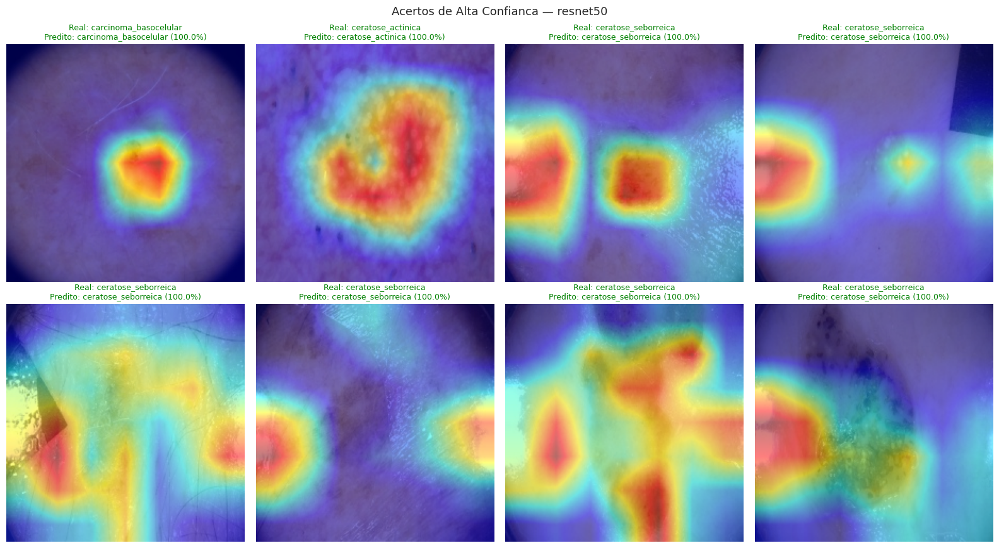

Salvo: /content/data/processed/gradcam/gradcam_acertos_de_alta_confianca_resnet50.png

--- Gerando Grad-CAM: Falsos Negativos de Melanoma (8 exemplos) ---


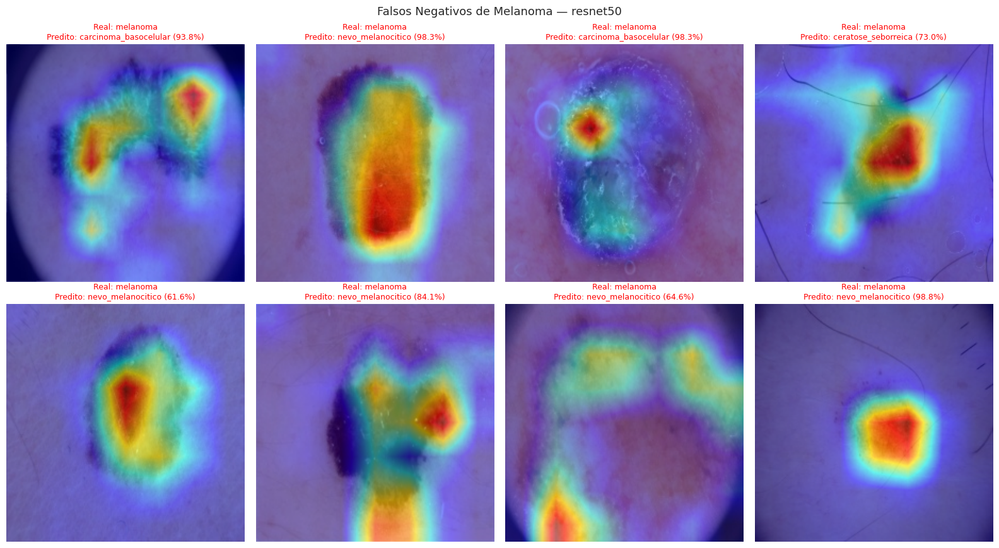

Salvo: /content/data/processed/gradcam/gradcam_falsos_negativos_de_melanoma_resnet50.png

--- Gerando Grad-CAM: Falsos Positivos de Melanoma (8 exemplos) ---


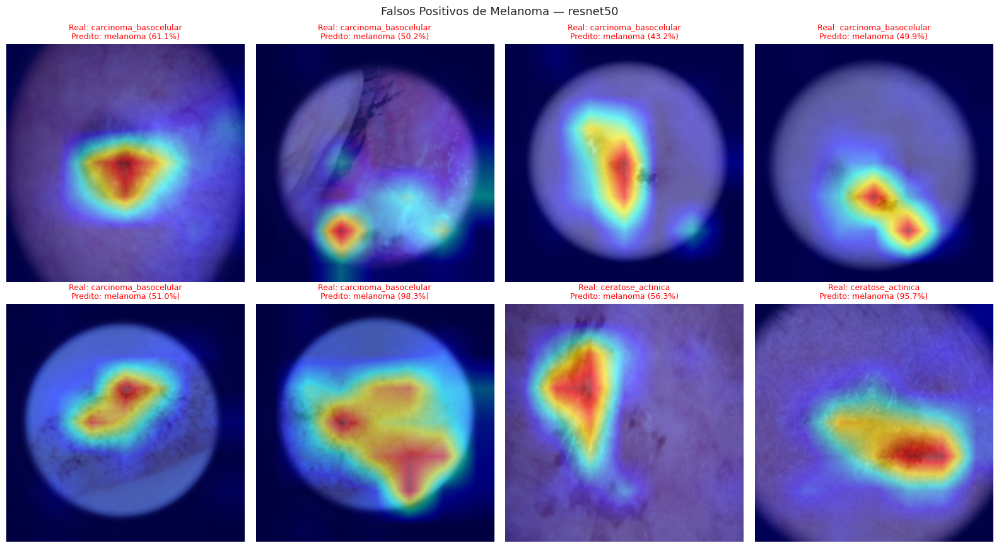

Salvo: /content/data/processed/gradcam/gradcam_falsos_positivos_de_melanoma_resnet50.png

--- Gerando Grad-CAM: Erros com Alta Confianca (geral) (8 exemplos) ---


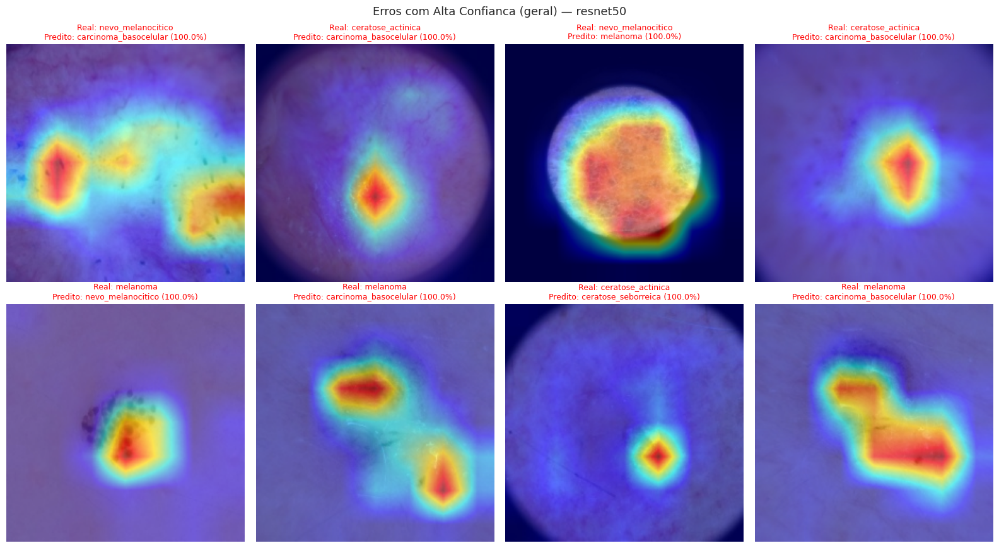

Salvo: /content/data/processed/gradcam/gradcam_erros_com_alta_confianca_(geral)_resnet50.png

[RESUMO CLÍNICO — resnet50] Falsos negativos de melanoma: 266/607 (43.8% dos melanomas reais foram classificados incorretamente como outra coisa)

Grad-CAM: efficientnet_b0
Coletando predições no conjunto de teste...
Selecionando grupos de análise qualitativa...

--- Gerando Grad-CAM: Acertos de Alta Confianca (8 exemplos) ---


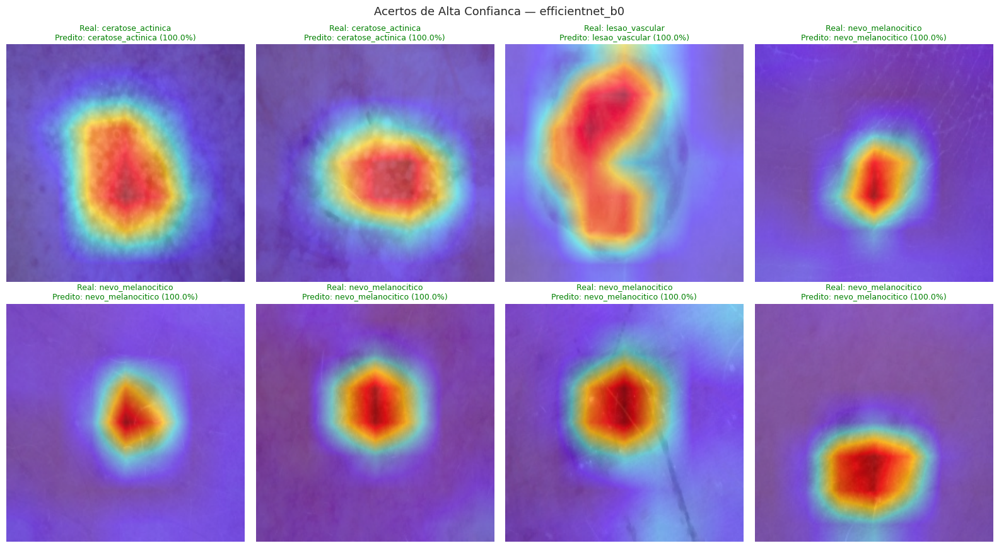

Salvo: /content/data/processed/gradcam/gradcam_acertos_de_alta_confianca_efficientnet_b0.png

--- Gerando Grad-CAM: Falsos Negativos de Melanoma (8 exemplos) ---


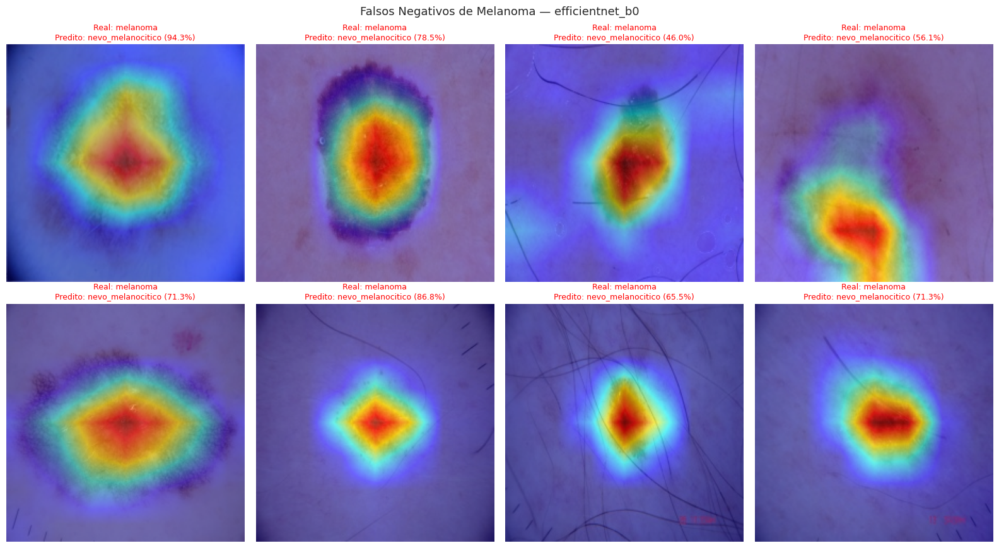

Salvo: /content/data/processed/gradcam/gradcam_falsos_negativos_de_melanoma_efficientnet_b0.png

--- Gerando Grad-CAM: Falsos Positivos de Melanoma (8 exemplos) ---


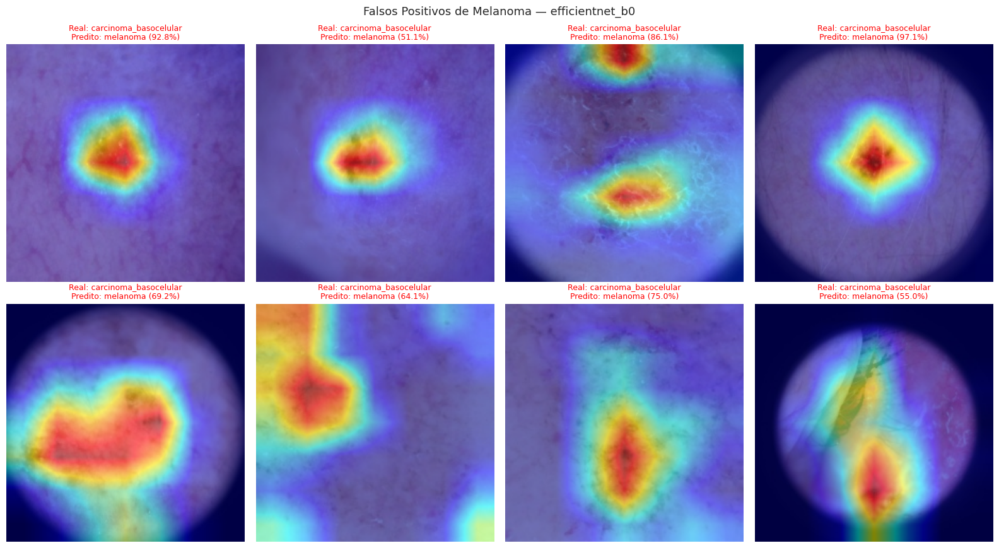

Salvo: /content/data/processed/gradcam/gradcam_falsos_positivos_de_melanoma_efficientnet_b0.png

--- Gerando Grad-CAM: Erros com Alta Confianca (geral) (8 exemplos) ---


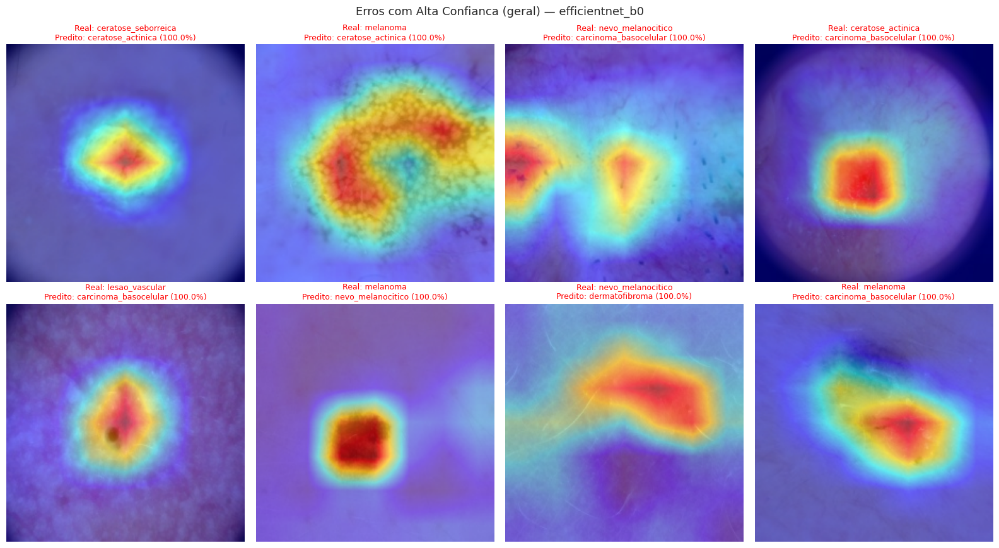

Salvo: /content/data/processed/gradcam/gradcam_erros_com_alta_confianca_(geral)_efficientnet_b0.png

[RESUMO CLÍNICO — efficientnet_b0] Falsos negativos de melanoma: 233/607 (38.4% dos melanomas reais foram classificados incorretamente como outra coisa)

ARQUIVOS GERADOS EM: /content/data/processed/gradcam
  - gradcam_acertos_de_alta_confianca_efficientnet_b0.png
  - gradcam_acertos_de_alta_confianca_resnet50.png
  - gradcam_erros_com_alta_confianca_(geral)_efficientnet_b0.png
  - gradcam_erros_com_alta_confianca_(geral)_resnet50.png
  - gradcam_falsos_negativos_de_melanoma_efficientnet_b0.png
  - gradcam_falsos_negativos_de_melanoma_resnet50.png
  - gradcam_falsos_positivos_de_melanoma_efficientnet_b0.png
  - gradcam_falsos_positivos_de_melanoma_resnet50.png


In [ ]:
# ============================================================
# EXECUÇÃO
# ============================================================
if __name__ == "__main__":
    print("Carregando DataLoaders...")
    _, _, test_loader, mapa_classes = criar_dataloaders()
    nomes_classes = sorted(mapa_classes, key=lambda k: mapa_classes[k])
    num_classes = len(nomes_classes)

    if NOME_CLASSE_MELANOMA not in mapa_classes:
        print(f"[AVISO] Classe '{NOME_CLASSE_MELANOMA}' não encontrada em mapa_classes: "
              f"{list(mapa_classes.keys())}. Ajuste a variável NOME_CLASSE_MELANOMA no topo do script.")

    for arquitetura in ["resnet50", "efficientnet_b0"]:
        print("\n" + "=" * 60)
        print(f"Grad-CAM: {arquitetura}")
        print("=" * 60)

        modelo, camada_alvo = carregar_modelo_e_camada_alvo(arquitetura, num_classes)

        print("Coletando predições no conjunto de teste...")
        registros = coletar_predicoes_com_imagens(modelo, test_loader)

        print("Selecionando grupos de análise qualitativa...")
        grupos = selecionar_grupos_analise(registros, mapa_classes)

        for chave_grupo, titulo in [
            ("acertos_alta_confianca", "Acertos de Alta Confianca"),
            ("falsos_negativos_melanoma", "Falsos Negativos de Melanoma"),
            ("falsos_positivos_melanoma", "Falsos Positivos de Melanoma"),
            ("erros_alta_confianca", "Erros com Alta Confianca (geral)"),
        ]:
            print(f"\n--- Gerando Grad-CAM: {titulo} ({len(grupos[chave_grupo])} exemplos) ---")
            gerar_grade_gradcam(modelo, camada_alvo, grupos[chave_grupo],
                                  nomes_classes, titulo, arquitetura)

        # Resumo numérico da análise qualitativa
        n_fn_melanoma = len([
            r for r in registros
            if mapa_classes.get(NOME_CLASSE_MELANOMA) is not None
            and r["rotulo_verdadeiro"] == mapa_classes[NOME_CLASSE_MELANOMA]
            and r["predicao"] != mapa_classes[NOME_CLASSE_MELANOMA]
        ])
        n_total_melanoma = len([
            r for r in registros
            if mapa_classes.get(NOME_CLASSE_MELANOMA) is not None
            and r["rotulo_verdadeiro"] == mapa_classes[NOME_CLASSE_MELANOMA]
        ])

        if n_total_melanoma > 0:
            print(f"\n[RESUMO CLÍNICO — {arquitetura}] "
                  f"Falsos negativos de melanoma: {n_fn_melanoma}/{n_total_melanoma} "
                  f"({n_fn_melanoma/n_total_melanoma*100:.1f}% dos melanomas reais "
                  f"foram classificados incorretamente como outra coisa)")

        del modelo
        torch.cuda.empty_cache()

    print("\n" + "=" * 70)
    print("ARQUIVOS GERADOS EM:", SAIDA_GRADCAM)
    print("=" * 70)
    for arquivo in sorted(os.listdir(SAIDA_GRADCAM)):
        print(f"  - {arquivo}")